In [1]:
# imports
import numpy as np
import matplotlib.pyplot as plt
import math
import pandas as pd
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
import itertools
from statsmodels.stats.multitest import multipletests
from scipy.stats import ttest_ind_from_stats
from matplotlib.colors import to_rgba

In [2]:
# load data
# OLD gibco
# NEW Millipore

# tubes
act_tubes = pd.read_parquet('act_tubes.parquet')
OD_tubes = pd.read_parquet('OD_tubes.parquet')

# sf [0] & 700 mL (non-usable)
act_sf_br = pd.read_parquet('act_ALE7_newtryp.parquet')
OD_sf_br = pd.read_parquet('OD_ALE7_newtryp.parquet')

# 700 mL
act_br_0506 = pd.read_parquet('act_ALE7_newtryp_0906.parquet')
OD_br_0506 = pd.read_parquet('OD_ALE7_newtryp_0906.parquet')

# br OLD
act_br_gibco = pd.read_parquet('../batch runs 700 mL/act_ALE7_summary.parquet')
OD_br_gibco = pd.read_parquet('../batch runs 700 mL/OD_ALE7_summary.parquet')

# sf OLD
act_ALE7_sf = pd.read_parquet('../shakeflasks runs/act_ALE_7_summary.parquet')
OD_ALE7_sf = pd.read_parquet('../shakeflasks runs/OD_ALE_7_summary.parquet')

# 20 L NEW
act_ALE7_20L = pd.read_parquet('../batch runs 20L/act_ALE7_20L.parquet')
OD_ALE7_20L = pd.read_parquet('../batch runs 20L/OD_ALE7_20L.parquet')

In [3]:
# ---------- significance functions ----------

def extract_pool5(dfs, prefix):
    data = {}
    for name, df in dfs.items():
        row = df[df[f"{prefix}_pool"] == 5].iloc[0]
        data[name] = {
            "mean": row[f"{prefix}_mean"],
            "std": row[f"{prefix}_std"],
            "n": row[f"{prefix}_n"],
        }
    return data

# pairwise comparisons
def planned_pairwise_tests(data, pairs, adjust_method="holm"):
    results = []

    for g1, g2 in pairs:
        d1 = data[g1]
        d2 = data[g2]

        t, p = ttest_ind_from_stats(
            mean1=d1["mean"], std1=d1["std"], nobs1=d1["n"],
            mean2=d2["mean"], std2=d2["std"], nobs2=d2["n"],
            equal_var=False
        )

        results.append({
            "group1": g1,
            "group2": g2,
            "p_value": p
        })

    results = pd.DataFrame(results)

    if len(results) > 0:
        _, p_adj, _, _ = multipletests(results["p_value"], method=adjust_method)
        results["p_adj"] = p_adj
        results["stars"] = results["p_adj"].apply(p_to_stars)

    return results

# correct for mutiple testing
def adjust_pvalues(df):
    _, p_adj, _, _ = multipletests(df["p_value"], method="holm")
    df["p_adj"] = p_adj
    return df

# ---------- plotting helpers ----------
def p_to_stars(p):
    if p < 0.001:
        return "***"
    elif p < 0.01:
        return "**"
    elif p < 0.05:
        return "*"
    else:
        return ""


def df_to_bracket_pairs(df, xmap, p_col="p_adj"):
    pairs = []

    for _, row in df.iterrows():
        label = row["stars"] if "stars" in df.columns else p_to_stars(row[p_col])
        if label == "":
            continue

        pairs.append({
            "x1": xmap[row["group1"]],
            "x2": xmap[row["group2"]],
            "label": label,
            "group1": row["group1"],
            "group2": row["group2"],
        })

    return pairs


def add_sig_bracket(ax, x1, x2, y, h, text):
    ax.plot([x1, x1, x2, x2], [y, y+h, y+h, y],
            linewidth=1, color="black")
    ax.text((x1 + x2) / 2, y + h, text,
            ha="center", va="bottom", fontsize=10)

def add_sig_brackets_grouped(ax, bracket_pairs, height_lookup, h=None, gap=None, text_offset=None):
    """
    bracket_pairs: list of dicts with keys x1, x2, label, group1, group2
    height_lookup: dict mapping each bar key to top y-value (mean + std)
    """
    if not bracket_pairs:
        return

    all_tops = [v for v in height_lookup.values() if not np.isnan(v)]
    ymax = max(all_tops)

    if h is None:
        h = 0.03 * ymax if ymax > 0 else 0.05
    if gap is None:
        gap = 0.05 * ymax if ymax > 0 else 0.08
    if text_offset is None:
        text_offset = 0.01 * ymax if ymax > 0 else 0.02

    current_top = ymax

    for pair in bracket_pairs:
        local_top = max(height_lookup[pair["group1"]], height_lookup[pair["group2"]])
        y = local_top + gap
        add_sig_bracket(ax, pair["x1"], pair["x2"], y, h, pair["label"])
        current_top = max(current_top, y + h + text_offset)

    ax.set_ylim(top=current_top + 2*gap)

In [ ]:
# calculate significance
# define comparisons
pairs = [
    ("gibco_tube", "milli_tube"),
    ('gibco_sf', 'milli_sf'),
    ('gibco_br', 'milli_br')
]

# OD
# stats dictionary
od_stats = {
    "gibco_tube": {"mean": OD_tubes['mean_OD'].iloc[0], "std": OD_tubes['std_OD'].iloc[0],   "n": 3},
    "milli_tube":{"mean": OD_tubes['mean_OD'].iloc[1], "std": OD_tubes['std_OD'].iloc[1], "n": 3},
    "gibco_sf":{"mean": OD_ALE7_sf['mean_1_3'].iloc[-1], "std": OD_ALE7_sf['std_1_3'].iloc[-1], "n": 3},
    "milli_sf":{"mean": OD_sf_br['mean_OD'].iloc[0], "std": OD_sf_br['std_OD'].iloc[0], "n": 3},
    "gibco_br":{"mean": OD_br_gibco['mean_OD'].iloc[-1], "std": OD_br_gibco['std_OD'].iloc[-1], "n": 3},
    "milli_br":{"mean": OD_br_0506['mean_OD'].iloc[-1], "std": OD_br_0506['std_OD'].iloc[-1], "n": 3},
    'milli_20L': {'mean': OD_ALE7_20L['mean_OD'].iloc[-1], 'std': OD_ALE7_20L['std_OD'].iloc[-1], 'n': 2},
}

# volumetric activity
# stats dictionary
vol_stats = {
    "gibco_tube": {"mean": act_tubes['vol_mean'].iloc[0], "std": act_tubes['vol_std'].iloc[0],   "n": act_tubes['vol_n'].iloc[0]},
    "milli_tube":{"mean": act_tubes['vol_mean'].iloc[1], "std": act_tubes['vol_std'].iloc[1], "n": act_tubes['vol_n'].iloc[1]},
    "gibco_sf":{"mean": act_ALE7_sf['vol_mean'].iloc[-1], "std": act_ALE7_sf['vol_std'].iloc[-1], "n": 3},
    "milli_sf":{"mean": act_sf_br['vol_mean'].iloc[0], "std": act_sf_br['vol_std'].iloc[0], "n": 3},
    "gibco_br":{"mean": act_br_gibco['vol_mean'].iloc[-1], "std": act_br_gibco['vol_std'].iloc[-1], "n": 3},
    "milli_br":{"mean": act_br_0506['vol_mean'].iloc[-1], "std": act_br_0506['vol_std'].iloc[-1], "n": 3},
    'milli_20L': {'mean': act_ALE7_20L['vol_mean'].iloc[-1], 'std': act_ALE7_20L['vol_std'].iloc[-1], 'n': 2},
}
    
# normalized activity
# stats dictionary
norm_stats = {
    "gibco_tube": {"mean": act_tubes['norm_mean'].iloc[0], "std": act_tubes['norm_std'].iloc[0],   "n": act_tubes['norm_n'].iloc[0]},
    "milli_tube":{"mean": act_tubes['norm_mean'].iloc[1], "std": act_tubes['norm_std'].iloc[1], "n": act_tubes['norm_n'].iloc[1]},
    "gibco_sf":{"mean": act_ALE7_sf['norm_mean'].iloc[-1], "std": act_ALE7_sf['norm_std'].iloc[-1], "n": 3},
    "milli_sf":{"mean": act_sf_br['norm_mean'].iloc[0], "std": act_sf_br['norm_std'].iloc[0], "n": 3},
    "gibco_br":{"mean": act_br_gibco['norm_mean'].iloc[-1], "std": act_br_gibco['norm_std'].iloc[-1], "n": 3},
    "milli_br":{"mean": act_br_0506['norm_mean'].iloc[-1], "std": act_br_0506['norm_std'].iloc[-1], "n": 3},
    'milli_20L': {'mean': act_ALE7_20L['norm_mean'].iloc[-1], 'std': act_ALE7_20L['norm_std'].iloc[-1], 'n': 2},
}

# run test
vol_results = planned_pairwise_tests(vol_stats, pairs, adjust_method="holm")
norm_results = planned_pairwise_tests(norm_stats, pairs, adjust_method="holm")
od_results = planned_pairwise_tests(od_stats, pairs, adjust_method="holm")

# print results
print(vol_results)
print(norm_results)
print(od_results)

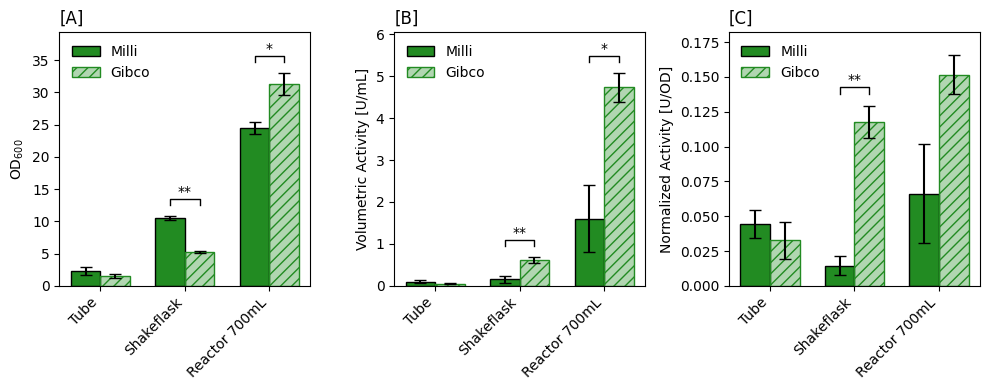

In [ ]:
# PLOTS without 20 L
groups = ["Tube", "Shakeflask", "Reactor 700mL"]
conditions = ["Millipore", "Gibco"]

plot_keys = {
    "Tube": {
        "Millipore": "milli_tube",
        "Gibco": "gibco_tube",
    },
    "Shakeflask": {
        "Millipore": "milli_sf",
        "Gibco": "gibco_sf",
    },
    "Reactor 700mL": {
        "Millipore": "milli_br",
        "Gibco": "gibco_br",
    },
}

colors = {
    "Millipore": "forestgreen",
    "Gibco": "forestgreen",
}

width = 0.35
xpos = np.arange(len(groups))

fig, axs = plt.subplots(1, 3, figsize=(10, 4))

ax_A = axs[0]   # OD
ax_B = axs[1]   # volumetric
ax_C = axs[2]   # normalized

def make_key(condition, group):
    return f"{condition}_{group.lower()}"


def plot_endpoint(ax, stats, ylabel, title):
    for i, group in enumerate(groups):
        for j, condition in enumerate(conditions):

            key = plot_keys[group][condition]
            if key is None:
                continue

            x = xpos[i] + (j - 0.5) * width

            mean = stats[key]["mean"]
            std = stats[key]["std"]
            color = colors[condition]

            if condition == "Gibco":
                ax.bar(
                    x, mean, yerr=std, capsize=4, width=width,
                    facecolor=to_rgba(color, 0.35),
                    edgecolor=color,
                    hatch="///",
                    linewidth=1.0,
                    label="Gibco" if i == 0 else None,
                )
            else:
                ax.bar(
                    x, mean, yerr=std, capsize=4, width=width,
                    color=color,
                    edgecolor="black",
                    linewidth=1.0,
                    label="Milli" if i == 0 else None,
                )

    ax.set_xticks(xpos)
    ax.set_xticklabels(groups, rotation=45, ha='right')
    ax.set_ylabel(ylabel)
    ax.set_title(title, loc="left")
    ax.set_ylim(bottom=0)
    ax.legend(frameon=False)

# ---------------- A: OD endpoint ----------------
plot_endpoint(
    ax_A,
    od_stats,
    ylabel="OD$_{600}$",
    title="[A]"
)

# ---------------- B: volumetric endpoint ----------------
plot_endpoint(
    ax_B,
    vol_stats,
    ylabel="Volumetric Activity [U/mL]",
    title="[B]"
)

# ---------------- C: normalized endpoint ----------------
plot_endpoint(
    ax_C,
    norm_stats,
    ylabel="Normalized Activity [U/OD]",
    title="[C]"
)


# ---------------- significance brackets ----------------

xmap = {}

for i, group in enumerate(groups):
    for j, condition in enumerate(conditions):
        key = plot_keys[group][condition]
        if key is None:
            continue
        xmap[key] = xpos[i] + (j - 0.5) * width


height_lookup_vol = {
    k: v["mean"] + v["std"]
    for k, v in vol_stats.items()
}

height_lookup_norm = {
    k: v["mean"] + v["std"]
    for k, v in norm_stats.items()
}

height_lookup_od = {
    k: v["mean"] + v["std"]
    for k, v in od_stats.items()
}


bracket_pairs_A = df_to_bracket_pairs(od_results, xmap)
bracket_pairs_B = df_to_bracket_pairs(vol_results, xmap)
bracket_pairs_C = df_to_bracket_pairs(norm_results, xmap)

add_sig_brackets_grouped(ax_A, bracket_pairs_A, height_lookup_od)
add_sig_brackets_grouped(ax_B, bracket_pairs_B, height_lookup_vol)
add_sig_brackets_grouped(ax_C, bracket_pairs_C, height_lookup_norm)

plt.tight_layout()

#plt.savefig("paper_ALE7_trypcomp_wo20L.tiff", dpi=1000, bbox_inches="tight")
plt.show()